In [1]:
# ============================================================
# Celda 1: Importar librerías y configurar el KPI
# ============================================================
from lightgbm import LGBMClassifier
import sys
import os
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings('ignore')
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), '..')))
from cargar_datos import cargar_dataset_recontacto

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    classification_report, confusion_matrix, roc_auc_score, roc_curve,
    accuracy_score, precision_score, recall_score, f1_score,
    average_precision_score
)
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from xgboost import XGBClassifier

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 11

# ============ CAMBIAR SOLO ESTA LÍNEA EN CADA NOTEBOOK ============
KPI_SEL = 'KPI08'      # 'KPI01', 'KPI02', 'KPI07', 'KPI08' o 'KPI10'
# ===================================================================

FICHAS = {
    'KPI01': dict(nombre='Recontacto general', filtro=None,
                  formula='casos con recontacto a 7 días ÷ casos con resultado conocido',
                  base=41.5, meta=36.5),
    'KPI02': dict(nombre='Recontacto en motivos críticos (falla/queja)', filtro='motivos_criticos',
                  formula='recontactos a 7 días de casos por falla o queja ÷ casos por falla o queja con resultado conocido',
                  base=46.1, meta=40.5),
    'KPI07': dict(nombre='Recontacto en usuarios con historial', filtro='historial',
                  formula='recontactos a 7 días de usuarios con casos previos en 30 días ÷ casos de esos usuarios con resultado conocido',
                  base=50.4, meta=44.4),
    'KPI08': dict(nombre='Recontacto en canales de baja resolución (red social y correo)', filtro='canales_baja_resolucion',
                  formula='recontactos a 7 días en red social y correo ÷ casos en esos canales con resultado conocido',
                  base=44.3, meta=39.1),
    'KPI10': dict(nombre='Recontacto en turno nocturno y fin de semana', filtro='nocturno_finde',
                  formula='recontactos a 7 días en turno nocturno y fin de semana ÷ casos en esos turnos con resultado conocido',
                  base=44.1, meta=38.6),
}
_f = FICHAS[KPI_SEL]

# ------------------ CONFIGURACIÓN DEL KPI ------------------
KPI_ID = KPI_SEL
KPI_NOMBRE = _f['nombre']
FILTRO = _f['filtro']
KPI_FORMULA = _f['formula']

# ------------------ OBJETIVO Y META ------------------
OBJETIVO = 'Reducir la tasa de recontacto a 7 días en el Servicio Ciudadano 1800'

# Referencia externa (NO equivalente): 100% - 78% de resolución en primer contacto.
META_RECONTACTO = 22.0

# Ficha del KPI
LINEA_BASE = _f['base']     # tasa actual del segmento (%)
META_6M = _f['meta']        # meta a 6 meses (escenario del 15 %, supuesto a validar)
PLAZO = '6 meses'
UMBRAL_ALERTA = _f['base']  # si la tasa supera la línea base, se activa alerta

TARGET_DEF = ('es_recontacto: 1 = el usuario vuelve a contactar por el mismo motivo en 7 días; '
              '0 = no vuelve; los casos con resultado vacío (no consolidado) se excluyen del modelo')
# -----------------------------------------------------

os.makedirs('../informe_figuras', exist_ok=True)

def guardar(nombre):
    plt.savefig(f'../informe_figuras/{KPI_ID}_{nombre}.png', dpi=150, bbox_inches='tight')

print("✅ Librerías cargadas correctamente")
print(f"📌 {KPI_ID} - {KPI_NOMBRE}")
print(f"📐 Fórmula: {KPI_FORMULA}")
print(f"🎯 Objetivo: {OBJETIVO}")
print(f"📊 Línea base: {LINEA_BASE}% | 🎯 Meta {PLAZO}: ≤ {META_6M}% | 🚨 Umbral de alerta: > {UMBRAL_ALERTA}%")
print(f"🏁 Referencia de largo plazo (no equivalente): ≤ {META_RECONTACTO:.0f}%")
print(f"🔖 Target: {TARGET_DEF}")

✅ Librerías cargadas correctamente
📌 KPI08 - Recontacto en canales de baja resolución (red social y correo)
📐 Fórmula: recontactos a 7 días en red social y correo ÷ casos en esos canales con resultado conocido
🎯 Objetivo: Reducir la tasa de recontacto a 7 días en el Servicio Ciudadano 1800
📊 Línea base: 44.3% | 🎯 Meta 6 meses: ≤ 39.1% | 🚨 Umbral de alerta: > 44.3%
🏁 Referencia de largo plazo (no equivalente): ≤ 22%
🔖 Target: es_recontacto: 1 = el usuario vuelve a contactar por el mismo motivo en 7 días; 0 = no vuelve; los casos con resultado vacío (no consolidado) se excluyen del modelo


In [2]:
# ============================================================
# Celda 2: Cargar dataset desde SQL Server
# ============================================================
def filtrar(d, filtro):
    if filtro == 'motivos_criticos':
        d = d[(d.motivo_falla == 1) | (d.motivo_queja == 1)]
    elif filtro == 'historial':
        d = d[d.tiene_historial == 1]
    elif filtro == 'canales_baja_resolucion':
        d = d[(d.canal_red_social == 1) | (d.canal_correo == 1)]
    elif filtro == 'nocturno_finde':
        d = d[(d.turno_nocturno == 1) | (d.turno_fin_semana == 1)]
    return d.reset_index(drop=True)

print("=" * 70)
print(f"📊 CARGANDO DATASET - {KPI_ID}: {KPI_NOMBRE}")
print("=" * 70)

df_base = cargar_dataset_recontacto()
df = filtrar(df_base, FILTRO)

tasa_inicial = df['es_recontacto'].mean() * 100

print(f"\n✅ Dataset del KPI listo")
print(f"📏 Dimensiones: {df.shape[0]:,} filas × {df.shape[1]} columnas")
print(f"📈 Tasa de recontacto del KPI: {tasa_inicial:.2f}%")
print(f"📈 Tasa de recontacto global : {df_base['es_recontacto'].mean() * 100:.2f}%")
print(f"🏁 Meta {PLAZO}: ≤ {META_6M}% → brecha actual: {tasa_inicial - META_6M:.1f} puntos | referencia largo plazo: {META_RECONTACTO:.0f}%")

# Control: la línea base escrita en la Celda 1 debe coincidir con la tasa real
if abs(tasa_inicial - LINEA_BASE) > 0.5:
    print(f"⚠️ OJO: la línea base de la ficha ({LINEA_BASE}%) no coincide con la tasa real ({tasa_inicial:.1f}%). Revisar KPI_SEL.")
else:
    print(f"✅ La línea base de la ficha ({LINEA_BASE}%) coincide con la tasa real.")

📊 CARGANDO DATASET - KPI08: Recontacto en canales de baja resolución (red social y correo)
📊 CARGANDO DATASET DE RECONTACTO (KPI 1)
✅ Conexión exitosa a SQL Server
✅ Consulta ejecutada: 11,436 registros, 34 columnas

📏 Dimensiones: 11,436 filas × 34 columnas

🎯 Distribución del target:
es_recontacto
0    6687
1    4749
Name: count, dtype: int64

📈 Tasa de recontacto: 41.53%

✅ Dataset del KPI listo
📏 Dimensiones: 5,233 filas × 34 columnas
📈 Tasa de recontacto del KPI: 44.26%
📈 Tasa de recontacto global : 41.53%
🏁 Meta 6 meses: ≤ 39.1% → brecha actual: 5.2 puntos | referencia largo plazo: 22%
✅ La línea base de la ficha (44.3%) coincide con la tasa real.


In [3]:
# ============================================================
# Celda 3: Exploración inicial del dataset
# ============================================================
print("=" * 70)
print("🔍 EXPLORACIÓN INICIAL DEL DATASET")
print("=" * 70)

print(f"\n📋 Columnas del dataset ({len(df.columns)}):")
for i, col in enumerate(df.columns, 1):
    print(f"   {i:2d}. {col:28s} | Tipo: {str(df[col].dtype):8s} | Nulos: {df[col].isnull().sum()}")

target_counts = df['es_recontacto'].value_counts().sort_index()
print(f"\n🎯 Distribución del target (es_recontacto):")
print(target_counts)
print(f"\n📈 Tasa de recontacto: {df['es_recontacto'].mean() * 100:.2f}%")

print(f"\n🔑 VARIABLES OPERATIVAS CLAVE:")
for c in ['espera_seg', 'duracion_seg', 'transferencias', 'casos_previos_30d']:
    print(f"   • {c}: media {df[c].mean():.2f} | mediana {df[c].median():.2f} | máx {df[c].max():.0f}")

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

target_counts.plot(kind='bar', ax=axes[0, 0], color=['#2ecc71', '#e74c3c'])
axes[0, 0].set_title('Distribución del target', fontweight='bold')
axes[0, 0].set_xticklabels(['No recontacta (0)', 'Recontacta (1)'], rotation=0)
axes[0, 0].set_ylabel('Casos')
for i, v in enumerate(target_counts):
    axes[0, 0].text(i, v + max(target_counts) * 0.01, f'{v:,}', ha='center', fontweight='bold')

df['espera_seg'].hist(ax=axes[0, 1], bins=30, color='#3498db', edgecolor='black')
axes[0, 1].set_title('Distribución del tiempo de espera', fontweight='bold')
axes[0, 1].set_xlabel('Segundos de espera')

df['duracion_seg'].hist(ax=axes[1, 0], bins=30, color='#9b59b6', edgecolor='black')
axes[1, 0].set_title('Distribución de la duración de la atención', fontweight='bold')
axes[1, 0].set_xlabel('Segundos de duración')

tr = df['transferencias'].clip(upper=3)
tasa_tr = df.groupby(tr)['es_recontacto'].mean() * 100
etiquetas = [str(int(i)) if i < 3 else '3 o más' for i in tasa_tr.index]
axes[1, 1].bar(etiquetas, tasa_tr.values, color='#e67e22', edgecolor='black')
axes[1, 1].axhline(df['es_recontacto'].mean() * 100, color='gray', ls='--', label='Tasa del KPI')
axes[1, 1].set_title('Tasa de recontacto según transferencias', fontweight='bold')
axes[1, 1].set_xlabel('Transferencias')
axes[1, 1].set_ylabel('% recontacto')
axes[1, 1].legend()
for i, v in enumerate(tasa_tr.values):
    axes[1, 1].text(i, v + 0.8, f'{v:.1f}%', ha='center', fontweight='bold')

plt.tight_layout()
guardar('01_exploracion')
plt.show()

🔍 EXPLORACIÓN INICIAL DEL DATASET

📋 Columnas del dataset (34):
    1. id_interaccion               | Tipo: int64    | Nulos: 0
    2. es_recontacto                | Tipo: int64    | Nulos: 0
    3. duracion_seg                 | Tipo: int64    | Nulos: 0
    4. espera_seg                   | Tipo: int64    | Nulos: 0
    5. transferencias               | Tipo: int64    | Nulos: 0
    6. casos_previos_30d            | Tipo: int64    | Nulos: 0
    7. es_duracion_corta            | Tipo: int64    | Nulos: 0
    8. es_espera_alta               | Tipo: int64    | Nulos: 0
    9. es_multi_transferencia       | Tipo: int64    | Nulos: 0
   10. tiene_historial              | Tipo: int64    | Nulos: 0
   11. canal_chat                   | Tipo: int64    | Nulos: 0
   12. canal_correo                 | Tipo: int64    | Nulos: 0
   13. canal_red_social             | Tipo: int64    | Nulos: 0
   14. canal_telefono               | Tipo: int64    | Nulos: 0
   15. canal_sin_dato               | Ti

<Figure size 1500x1000 with 4 Axes>

In [4]:
# ============================================================
# Celda 4: Preprocesamiento de variables
# ============================================================
print("=" * 70)
print("🔧 PREPROCESAMIENTO DE VARIABLES")
print("=" * 70)

columnas_a_eliminar = ['id_interaccion', 'fecha_contacto', 'es_recontacto']
X = df.drop(columns=columnas_a_eliminar, errors='ignore')
y = df['es_recontacto']

print(f"\n📊 Features iniciales: {X.shape[1]} columnas")
print(f"🚫 Excluidas del modelo: {columnas_a_eliminar} (identificador, fecha y target)")

columnas_texto = X.select_dtypes(include=['object']).columns.tolist()
print(f"\n📝 Variables categóricas sin codificar: {columnas_texto if columnas_texto else 'ninguna (ya vienen en dummies)'}")
if columnas_texto:
    X = pd.get_dummies(X, columns=columnas_texto, drop_first=True)

columnas_bool = X.select_dtypes(include=['bool']).columns.tolist()
if columnas_bool:
    X = X.astype({c: 'int8' for c in columnas_bool})
    print(f"✅ {len(columnas_bool)} columnas booleanas convertidas a enteros")

nulos_antes = int(X.isnull().sum().sum())
X = X.fillna(0)
print(f"✅ Valores nulos rellenados: {nulos_antes} → {int(X.isnull().sum().sum())}")

# --- Quitar columnas constantes (p. ej. canal_chat/telefono/sin_dato = 0 al filtrar por red social OR correo) ---
constantes = [c for c in X.columns if X[c].nunique() <= 1]
if constantes:
    X = X.drop(columns=constantes)
    print(f"\n🧹 Columnas constantes eliminadas: {constantes}")

# --- Evitar colinealidad: una categoría de referencia por grupo de dummies ---
GRUPOS = ['canal_', 'motivo_', 'cola_', 'usuario_', 'turno_']
referencias = {}
for pref in GRUPOS:
    cols = [c for c in X.columns if c.startswith(pref)]
    if cols and (X[cols].sum(axis=1) == 1).all():      # el grupo suma 1 en todas las filas
        ref = max(cols, key=lambda c: X[c].sum())      # la más frecuente como referencia
        X = X.drop(columns=ref)
        referencias[pref.rstrip('_')] = ref

print("\n📌 Categorías de referencia (los coeficientes se leen frente a ellas):")
for g, r in referencias.items():
    print(f"   • {g:8s} → {r}")

print(f"\n📏 Features finales: {X.shape[1]} columnas")
for i, col in enumerate(X.columns, 1):
    print(f"  {i:2d}. {col}")

🔧 PREPROCESAMIENTO DE VARIABLES

📊 Features iniciales: 31 columnas
🚫 Excluidas del modelo: ['id_interaccion', 'fecha_contacto', 'es_recontacto'] (identificador, fecha y target)

📝 Variables categóricas sin codificar: ninguna (ya vienen en dummies)
✅ Valores nulos rellenados: 0 → 0

🧹 Columnas constantes eliminadas: ['canal_chat', 'canal_telefono', 'canal_sin_dato']

📌 Categorías de referencia (los coeficientes se leen frente a ellas):
   • canal    → canal_correo
   • motivo   → motivo_queja
   • cola     → cola_informacion
   • usuario  → usuario_recurrente
   • turno    → turno_am

📏 Features finales: 23 columnas
   1. duracion_seg
   2. espera_seg
   3. transferencias
   4. casos_previos_30d
   5. es_duracion_corta
   6. es_espera_alta
   7. es_multi_transferencia
   8. tiene_historial
   9. canal_red_social
  10. motivo_consulta
  11. motivo_falla
  12. motivo_cobro
  13. motivo_solicitud
  14. cola_facturacion
  15. cola_soporte
  16. cola_reclamos
  17. cola_tramites
  18. usuari

In [5]:
# ============================================================
# Celda 5: División del dataset (80% / 20%)
# ============================================================
print("=" * 70)
print("📊 DIVISIÓN TRAIN / TEST (80% / 20%)")
print("=" * 70)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"\n📏 Entrenamiento: {X_train.shape[0]:,} registros")
print(f"📏 Prueba:        {X_test.shape[0]:,} registros")
print(f"\n🎯 Clases en TRAIN:\n{y_train.value_counts(normalize=True).round(3)}")
print(f"\n🎯 Clases en TEST:\n{y_test.value_counts(normalize=True).round(3)}")
print("\n✅ División estratificada completada (proporción mantenida)")
print("✅ Variables estandarizadas con StandardScaler (ajustado solo con TRAIN)")

📊 DIVISIÓN TRAIN / TEST (80% / 20%)

📏 Entrenamiento: 4,186 registros
📏 Prueba:        1,047 registros

🎯 Clases en TRAIN:
es_recontacto
0    0.557
1    0.443
Name: proportion, dtype: float64

🎯 Clases en TEST:
es_recontacto
0    0.558
1    0.442
Name: proportion, dtype: float64

✅ División estratificada completada (proporción mantenida)
✅ Variables estandarizadas con StandardScaler (ajustado solo con TRAIN)


🤖 COMPARACIÓN DE 7 MODELOS
   ✅ 1. Regresión Logística     Accuracy 0.7966 | AUC 0.8836
   ✅ 2. Árbol de Decisión       Accuracy 0.7450 | AUC 0.8129
   ✅ 3. Random Forest           Accuracy 0.7784 | AUC 0.8625
   ✅ 4. XGBoost                 Accuracy 0.7813 | AUC 0.8616
   ✅ 5. LightGBM                Accuracy 0.7755 | AUC 0.8595
   ✅ 6. KNN (k=10)              Accuracy 0.7278 | AUC 0.8020
   ✅ 7. Naive Bayes             Accuracy 0.7641 | AUC 0.8362

📊 TABLA COMPARATIVA (ordenada por ROC-AUC)
                Modelo  Accuracy  Precision  Recall  F1-Score  ROC-AUC  Tiempo (s)
1. Regresión Logística    0.7966     0.7648  0.7797    0.7722   0.8836      0.0501
      3. Random Forest    0.7784     0.7495  0.7495    0.7495   0.8625      1.2629
            4. XGBoost    0.7813     0.7543  0.7495    0.7519   0.8616      2.5392
           5. LightGBM    0.7755     0.7457  0.7473    0.7465   0.8595      0.7011
        7. Naive Bayes    0.7641     0.7784  0.6523    0.7098   0.8362      0.0160
  2.

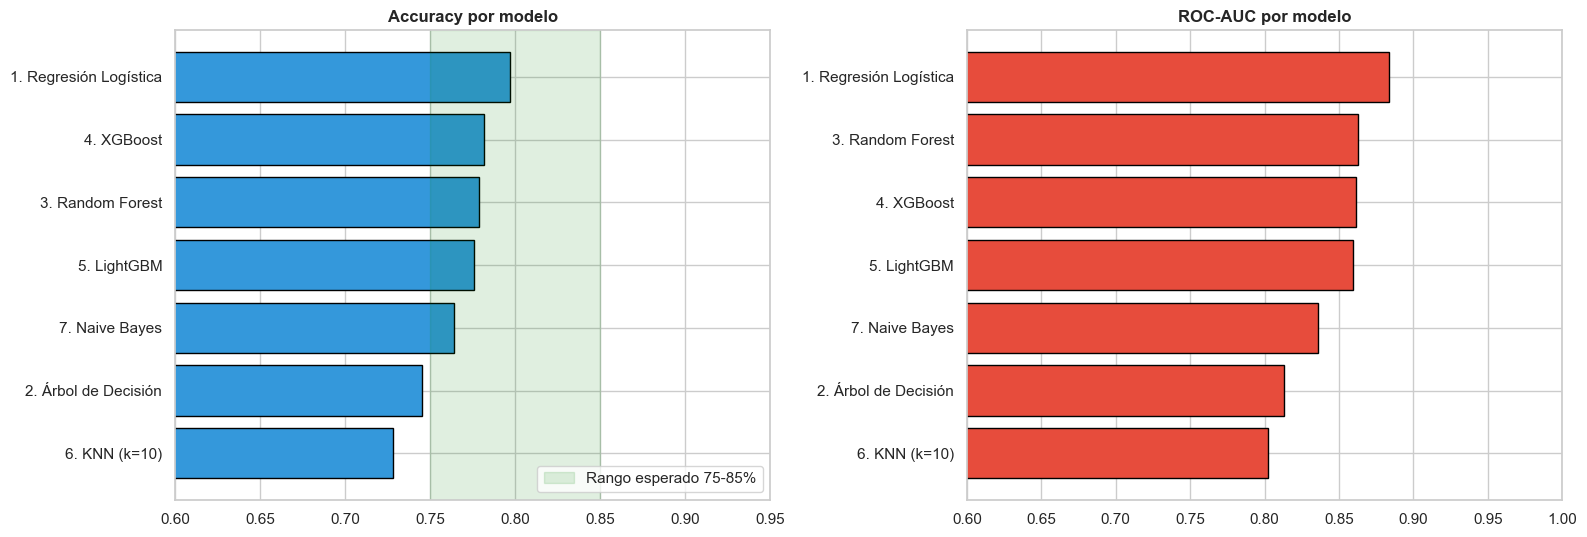

In [6]:
# ============================================================
# Celda 6: Comparación de modelos (selección del mejor)
# ============================================================
print("=" * 70)
print("🤖 COMPARACIÓN DE 7 MODELOS")
print("=" * 70)

ratio = (y_train == 0).sum() / (y_train == 1).sum()

modelos = {
    '1. Regresión Logística': LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42),
    '2. Árbol de Decisión': DecisionTreeClassifier(max_depth=8, min_samples_split=20, min_samples_leaf=10,
                                                   class_weight='balanced', random_state=42),
    '3. Random Forest': RandomForestClassifier(n_estimators=300, max_depth=10, min_samples_split=10,
                                               class_weight='balanced', random_state=42, n_jobs=-1),
    '4. XGBoost': XGBClassifier(n_estimators=600, max_depth=5, learning_rate=0.05,
                                scale_pos_weight=ratio, random_state=42, eval_metric='auc', verbosity=0),
    '5. LightGBM': LGBMClassifier(n_estimators=600, max_depth=5, learning_rate=0.05,
                                  scale_pos_weight=ratio, random_state=42, verbose=-1),
    '6. KNN (k=10)': KNeighborsClassifier(n_neighbors=10, weights='distance', n_jobs=-1),
    '7. Naive Bayes': GaussianNB(),
}
ESCALADOS = ['1. Regresión Logística', '6. KNN (k=10)']

resultados = []
for nombre, m in modelos.items():
    inicio = time.time()
    a, b = (X_train_scaled, X_test_scaled) if nombre in ESCALADOS else (X_train, X_test)
    m.fit(a, y_train)
    pred = m.predict(b)
    proba = m.predict_proba(b)[:, 1]
    resultados.append({
        'Modelo': nombre,
        'Accuracy': accuracy_score(y_test, pred),
        'Precision': precision_score(y_test, pred),
        'Recall': recall_score(y_test, pred),
        'F1-Score': f1_score(y_test, pred),
        'ROC-AUC': roc_auc_score(y_test, proba),
        'Tiempo (s)': time.time() - inicio,
    })
    print(f"   ✅ {nombre:26s} Accuracy {resultados[-1]['Accuracy']:.4f} | AUC {resultados[-1]['ROC-AUC']:.4f}")

df_res = pd.DataFrame(resultados).sort_values('ROC-AUC', ascending=False).reset_index(drop=True)
print("\n📊 TABLA COMPARATIVA (ordenada por ROC-AUC)")
print(df_res.round(4).to_string(index=False))

mejor = df_res.iloc[0]['Modelo']
print(f"\n🏆 MEJOR MODELO: {mejor}  (ROC-AUC {df_res.iloc[0]['ROC-AUC']:.4f})")

fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
orden = df_res.sort_values('Accuracy')
axes[0].barh(orden['Modelo'], orden['Accuracy'], color='#3498db', edgecolor='black')
axes[0].axvspan(0.75, 0.85, color='green', alpha=0.12, label='Rango esperado 75-85%')
axes[0].set_title('Accuracy por modelo', fontweight='bold')
axes[0].set_xlim(0.6, 0.95)
axes[0].legend(loc='lower right')
orden = df_res.sort_values('ROC-AUC')
axes[1].barh(orden['Modelo'], orden['ROC-AUC'], color='#e74c3c', edgecolor='black')
axes[1].set_title('ROC-AUC por modelo', fontweight='bold')
axes[1].set_xlim(0.6, 1.0)
plt.tight_layout()
guardar('02_comparacion_modelos')
plt.show()

In [7]:
# ============================================================
# Celda 7: Entrenamiento del modelo final (Regresión Logística)
# ============================================================
print("=" * 70)
print("🤖 ENTRENAMIENTO DEL MODELO FINAL: REGRESIÓN LOGÍSTICA")
print("=" * 70)

modelo = LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42)
print(f"\n🔄 Entrenando con {X_train.shape[0]:,} registros...")
modelo.fit(X_train_scaled, y_train)
print("✅ Modelo entrenado exitosamente")

cv = cross_val_score(modelo, X_train_scaled, y_train, cv=5, scoring='roc_auc')
print(f"\n🔁 Validación cruzada (5 particiones) ROC-AUC: {cv.mean():.4f} ± {cv.std():.4f}")

if mejor != '1. Regresión Logística':
    print(f"\n⚠️ OJO: en este KPI el mejor por AUC fue {mejor}. Revisar antes de justificar la Regresión Logística.")
else:
    print("\n✅ La Regresión Logística es el mejor modelo de la comparación para este KPI")

🤖 ENTRENAMIENTO DEL MODELO FINAL: REGRESIÓN LOGÍSTICA

🔄 Entrenando con 4,186 registros...
✅ Modelo entrenado exitosamente

🔁 Validación cruzada (5 particiones) ROC-AUC: 0.8849 ± 0.0088

✅ La Regresión Logística es el mejor modelo de la comparación para este KPI


In [8]:
# ============================================================
# Celda 8: Evaluación de métricas en el set de prueba
# ============================================================
print("=" * 70)
print("📊 EVALUACIÓN DEL MODELO EN SET DE PRUEBA")
print("=" * 70)

y_pred = modelo.predict(X_test_scaled)
y_pred_proba = modelo.predict_proba(X_test_scaled)[:, 1]

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
auc = roc_auc_score(y_test, y_pred_proba)
avg_precision = average_precision_score(y_test, y_pred_proba)

print(f"\n🎯 MÉTRICAS PRINCIPALES:")
print(f"   • Accuracy:       {accuracy:.4f} ({accuracy:.2%})")
print(f"   • Precision:      {precision:.4f}")
print(f"   • Recall:         {recall:.4f}")
print(f"   • F1-Score:       {f1:.4f}")
print(f"   • ROC-AUC:        {auc:.4f}")
print(f"   • Avg Precision:  {avg_precision:.4f}")

print(f"\n📋 REPORTE DE CLASIFICACIÓN COMPLETO:")
print("-" * 70)
print(classification_report(y_test, y_pred, target_names=['No recontacta (0)', 'Recontacta (1)']))

print(f"💡 INTERPRETACIÓN:")
print(f"   • ROC-AUC = {auc:.3f} indica un poder discriminatorio "
      f"{'excelente' if auc > 0.85 else 'bueno' if auc > 0.75 else 'moderado'}")
print(f"   • Accuracy {'dentro' if 0.75 <= accuracy <= 0.85 else 'fuera'} del rango esperado (75%-85%)")
print(f"   • {'No hay indicio de data leakage (accuracy < 90%)' if accuracy < 0.90 else 'ALERTA: accuracy > 90%, revisar posible data leakage'}")
print(f"   • CV-AUC {cv.mean():.3f} vs AUC de prueba {auc:.3f}: diferencia {abs(cv.mean() - auc):.3f} "
      f"({'sin sobreajuste evidente' if abs(cv.mean() - auc) < 0.03 else 'revisar sobreajuste'})")

📊 EVALUACIÓN DEL MODELO EN SET DE PRUEBA

🎯 MÉTRICAS PRINCIPALES:
   • Accuracy:       0.7966 (79.66%)
   • Precision:      0.7648
   • Recall:         0.7797
   • F1-Score:       0.7722
   • ROC-AUC:        0.8836
   • Avg Precision:  0.8687

📋 REPORTE DE CLASIFICACIÓN COMPLETO:
----------------------------------------------------------------------
                   precision    recall  f1-score   support

No recontacta (0)       0.82      0.81      0.82       584
   Recontacta (1)       0.76      0.78      0.77       463

         accuracy                           0.80      1047
        macro avg       0.79      0.79      0.79      1047
     weighted avg       0.80      0.80      0.80      1047

💡 INTERPRETACIÓN:
   • ROC-AUC = 0.884 indica un poder discriminatorio excelente
   • Accuracy dentro del rango esperado (75%-85%)
   • No hay indicio de data leakage (accuracy < 90%)
   • CV-AUC 0.885 vs AUC de prueba 0.884: diferencia 0.001 (sin sobreajuste evidente)


In [9]:
# ============================================================
# Celda 8b: Verificación anti-fuga de datos (data leakage)
# ============================================================
print("=" * 70)
print("🛡️ VERIFICACIÓN ANTI-FUGA DE DATOS")
print("=" * 70)

# 1) Ninguna variable del modelo contiene el resultado
sospechosas = [c for c in X.columns if 'recontacto' in c.lower()]
print(f"\n1) Variables con 'recontacto' en el nombre dentro del modelo: {sospechosas if sospechosas else 'ninguna ✅'}")

# 2) Ninguna variable por sí sola separa casi perfectamente el target
aucs = {}
for c in X.columns:
    if X[c].nunique() > 1:
        a = roc_auc_score(y, X[c])
        aucs[c] = max(a, 1 - a)
aucs = pd.Series(aucs).sort_values(ascending=False)
print(f"\n2) AUC individual más alto de una sola variable: {aucs.index[0]} = {aucs.iloc[0]:.3f}")
print(f"   {'✅ ninguna variable por sí sola explica el target (umbral de alerta: 0.95)' if aucs.iloc[0] < 0.95 else '⚠️ revisar: una variable casi separa el target'}")
print(aucs.head(5).round(3).to_string())

# 3) Rendimiento realista y estable
print(f"\n3) Accuracy {accuracy:.2%} (alerta si > 90%): {'✅' if accuracy < 0.90 else '⚠️'}")
print(f"4) CV-AUC {cv.mean():.3f} vs AUC prueba {auc:.3f} (diferencia {abs(cv.mean() - auc):.3f}): "
      f"{'✅ estable' if abs(cv.mean() - auc) < 0.03 else '⚠️ revisar'}")

print("""
5) Diseño de las variables (variables congeladas en el tiempo):
   • duracion_seg, espera_seg y transferencias describen el contacto original, no el recontacto.
   • casos_previos_30d se calcula solo con contactos ANTERIORES del mismo usuario.
   • Se excluyen del modelo: id_interaccion, fecha_contacto y el propio target.
""")

🛡️ VERIFICACIÓN ANTI-FUGA DE DATOS

1) Variables con 'recontacto' en el nombre dentro del modelo: ninguna ✅

2) AUC individual más alto de una sola variable: transferencias = 0.739
   ✅ ninguna variable por sí sola explica el target (umbral de alerta: 0.95)
transferencias            0.739
espera_seg                0.716
es_espera_alta            0.638
es_multi_transferencia    0.636
casos_previos_30d         0.633

3) Accuracy 79.66% (alerta si > 90%): ✅
4) CV-AUC 0.885 vs AUC prueba 0.884 (diferencia 0.001): ✅ estable

5) Diseño de las variables (variables congeladas en el tiempo):
   • duracion_seg, espera_seg y transferencias describen el contacto original, no el recontacto.
   • casos_previos_30d se calcula solo con contactos ANTERIORES del mismo usuario.
   • Se excluyen del modelo: id_interaccion, fecha_contacto y el propio target.



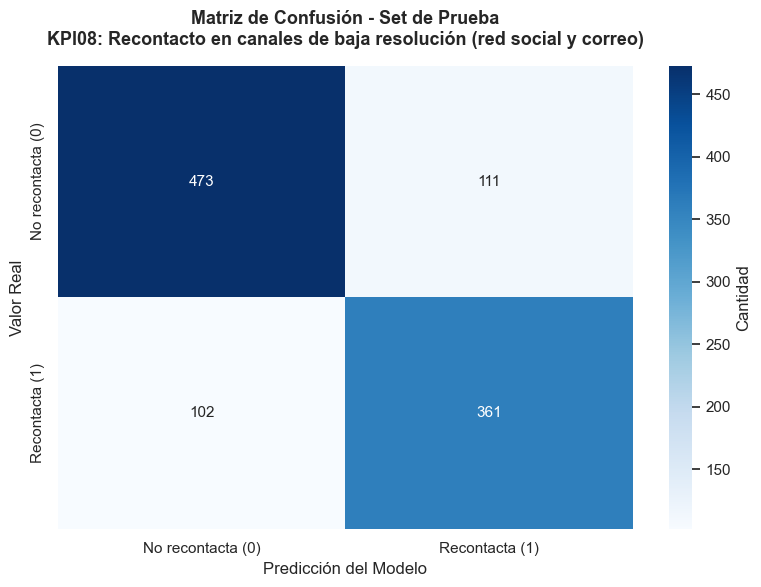


📊 DESGLOSE DE LA MATRIZ:
   • Verdaderos Positivos (VP):   361 → Recontactos detectados correctamente
   • Verdaderos Negativos (VN):   473 → Casos resueltos identificados correctamente
   • Falsos Positivos (FP):       111 → Alarmas falsas (se predijo recontacto y no ocurrió)
   • Falsos Negativos (FN):       102 → Recontactos que el modelo no detectó

💼 LECTURA OPERATIVA:
   • De 463 recontactos reales, el modelo anticipó 361 (78.0%)
   • De 472 casos marcados como riesgo, 361 sí recontactaron (76.5%)
   • Seguimientos que serían innecesarios: 111


In [10]:
# ============================================================
# Celda 9: Matriz de confusión
# ============================================================
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['No recontacta (0)', 'Recontacta (1)'],
            yticklabels=['No recontacta (0)', 'Recontacta (1)'],
            cbar_kws={'label': 'Cantidad'})
plt.title(f'Matriz de Confusión - Set de Prueba\n{KPI_ID}: {KPI_NOMBRE}', fontsize=13, fontweight='bold', pad=15)
plt.ylabel('Valor Real')
plt.xlabel('Predicción del Modelo')
plt.tight_layout()
guardar('03_matriz_confusion')
plt.show()

tn, fp, fn, tp = cm.ravel()
print(f"\n📊 DESGLOSE DE LA MATRIZ:")
print(f"   • Verdaderos Positivos (VP): {tp:5d} → Recontactos detectados correctamente")
print(f"   • Verdaderos Negativos (VN): {tn:5d} → Casos resueltos identificados correctamente")
print(f"   • Falsos Positivos (FP):     {fp:5d} → Alarmas falsas (se predijo recontacto y no ocurrió)")
print(f"   • Falsos Negativos (FN):     {fn:5d} → Recontactos que el modelo no detectó")

print(f"\n💼 LECTURA OPERATIVA:")
print(f"   • De {tp + fn:,} recontactos reales, el modelo anticipó {tp:,} ({tp / (tp + fn):.1%})")
print(f"   • De {tp + fp:,} casos marcados como riesgo, {tp:,} sí recontactaron ({tp / (tp + fp):.1%})")
print(f"   • Seguimientos que serían innecesarios: {fp:,}")

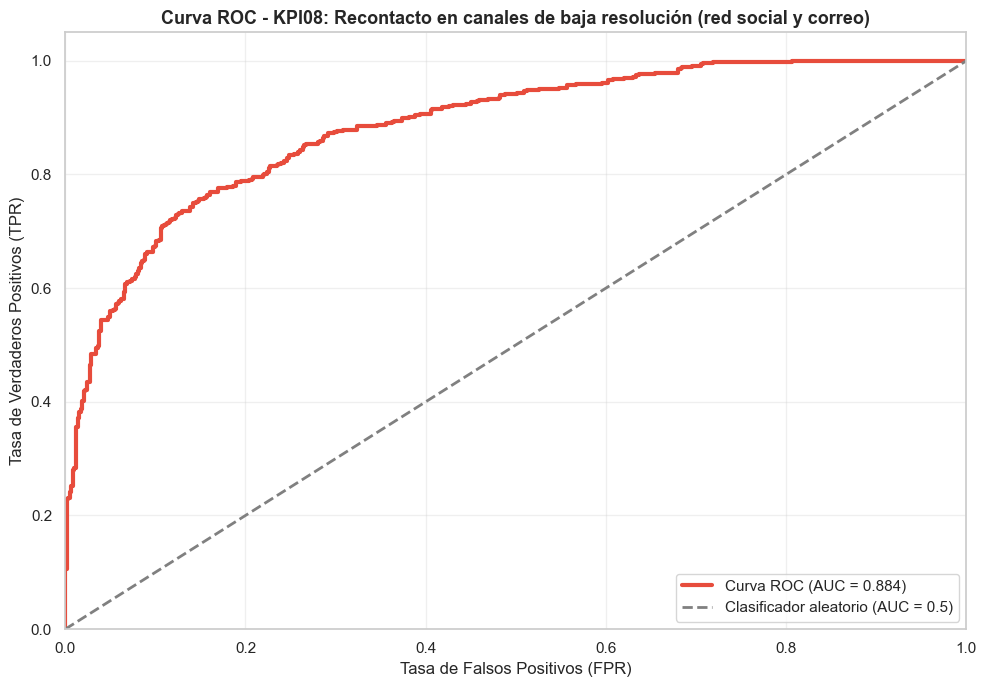


🎯 UMBRAL ÓPTIMO (máximo de TPR - FPR):
   • Umbral: 0.537
   • TPR en ese punto: 0.769
   • FPR en ese punto: 0.161


In [11]:
# ============================================================
# Celda 10: Curva ROC
# ============================================================
fpr, tpr, thresholds = roc_curve(y_test, y_pred_proba)

plt.figure(figsize=(10, 7))
plt.plot(fpr, tpr, color='#e74c3c', lw=3, label=f'Curva ROC (AUC = {auc:.3f})')
plt.plot([0, 1], [0, 1], color='gray', lw=2, linestyle='--', label='Clasificador aleatorio (AUC = 0.5)')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Tasa de Falsos Positivos (FPR)')
plt.ylabel('Tasa de Verdaderos Positivos (TPR)')
plt.title(f'Curva ROC - {KPI_ID}: {KPI_NOMBRE}', fontsize=13, fontweight='bold')
plt.legend(loc="lower right")
plt.grid(True, alpha=0.3)
plt.tight_layout()
guardar('04_curva_roc')
plt.show()

idx_optimo = np.argmax(tpr - fpr)
umbral_optimo = thresholds[idx_optimo]
print(f"\n🎯 UMBRAL ÓPTIMO (máximo de TPR - FPR):")
print(f"   • Umbral: {umbral_optimo:.3f}")
print(f"   • TPR en ese punto: {tpr[idx_optimo]:.3f}")
print(f"   • FPR en ese punto: {fpr[idx_optimo]:.3f}")

🔍 VARIABLES MÁS ASOCIADAS AL RECONTACTO (COEFICIENTES)

📌 Los coeficientes se leen frente a la categoría de referencia de cada grupo:
   • canal    → canal_correo
   • motivo   → motivo_queja
   • cola     → cola_informacion
   • usuario  → usuario_recurrente
   • turno    → turno_am

📊 TOP 15 VARIABLES (odds ratio por cada desviación estándar):
----------------------------------------------------------------------
    1. transferencias               | coef +1.6410 | OR 5.160 | ↑ sube la prob.
    2. espera_seg                   | coef +0.8852 | OR 2.423 | ↑ sube la prob.
    3. casos_previos_30d            | coef +0.8746 | OR 2.398 | ↑ sube la prob.
    4. cola_reclamos                | coef -0.6281 | OR 0.534 | ↓ baja la prob.
    5. cola_soporte                 | coef -0.4689 | OR 0.626 | ↓ baja la prob.
    6. es_duracion_corta            | coef +0.4012 | OR 1.494 | ↑ sube la prob.
    7. usuario_adulto_mayor         | coef +0.3728 | OR 1.452 | ↑ sube la prob.
    8. duracion_seg  

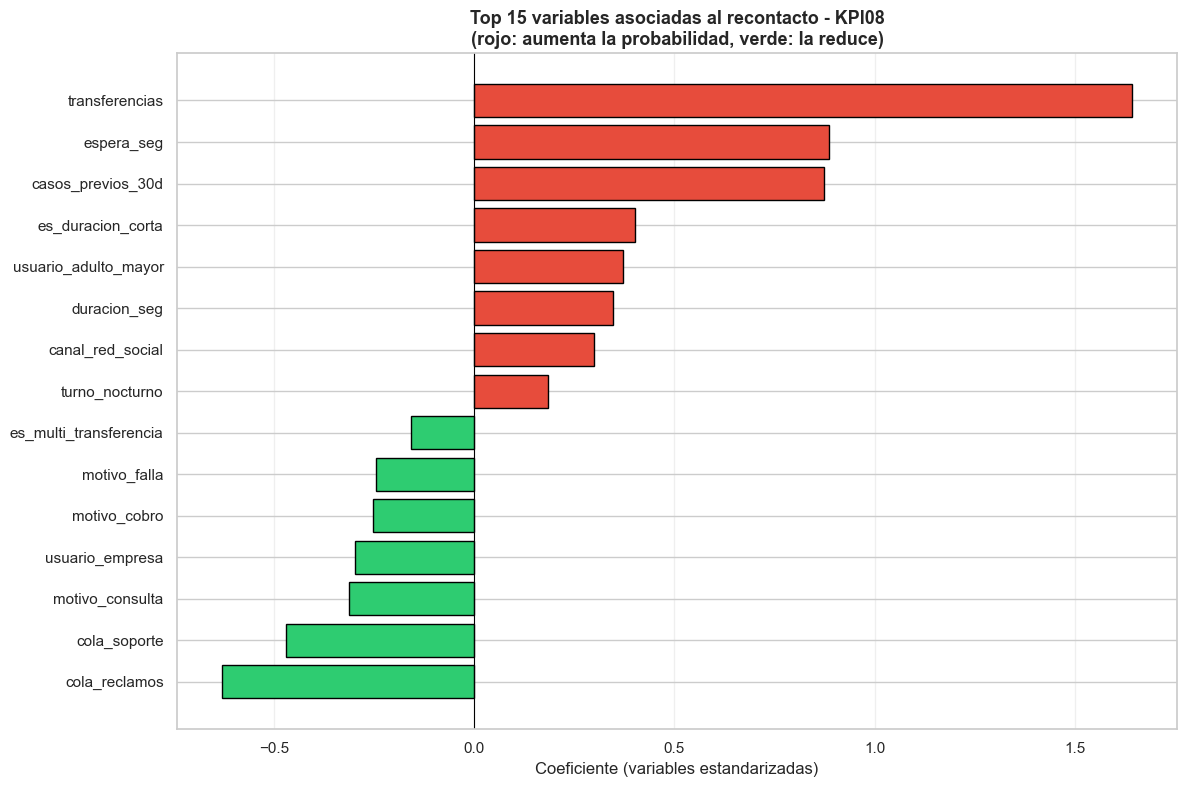


⚠️ Los coeficientes indican ASOCIACIÓN, no causalidad.


In [12]:
# ============================================================
# Celda 11: Variables más asociadas al recontacto
# ============================================================
print("=" * 70)
print("🔍 VARIABLES MÁS ASOCIADAS AL RECONTACTO (COEFICIENTES)")
print("=" * 70)

print("\n📌 Los coeficientes se leen frente a la categoría de referencia de cada grupo:")
for g, r in referencias.items():
    print(f"   • {g:8s} → {r}")

df_coef = pd.DataFrame({'Variable': X.columns, 'Coeficiente': modelo.coef_[0]})
df_coef['Odds ratio'] = np.exp(df_coef['Coeficiente'])
df_coef['Abs'] = df_coef['Coeficiente'].abs()
df_coef = df_coef.sort_values('Abs', ascending=False).reset_index(drop=True)
top15 = df_coef.head(15)

print(f"\n📊 TOP 15 VARIABLES (odds ratio por cada desviación estándar):")
print("-" * 70)
for i, r in top15.iterrows():
    signo = '↑ sube' if r['Coeficiente'] > 0 else '↓ baja'
    print(f"   {i + 1:2d}. {r['Variable']:28s} | coef {r['Coeficiente']:+.4f} | OR {r['Odds ratio']:.3f} | {signo} la prob.")

plot_data = top15.sort_values('Coeficiente')
colores = ['#e74c3c' if c > 0 else '#2ecc71' for c in plot_data['Coeficiente']]
plt.figure(figsize=(12, 8))
plt.barh(plot_data['Variable'], plot_data['Coeficiente'], color=colores, edgecolor='black')
plt.axvline(0, color='black', lw=0.8)
plt.xlabel('Coeficiente (variables estandarizadas)')
plt.title(f'Top 15 variables asociadas al recontacto - {KPI_ID}\n(rojo: aumenta la probabilidad, verde: la reduce)',
          fontsize=13, fontweight='bold')
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
guardar('05_coeficientes')
plt.show()

print("\n⚠️ Los coeficientes indican ASOCIACIÓN, no causalidad.")

💼 RECONTACTO POR SEGMENTO


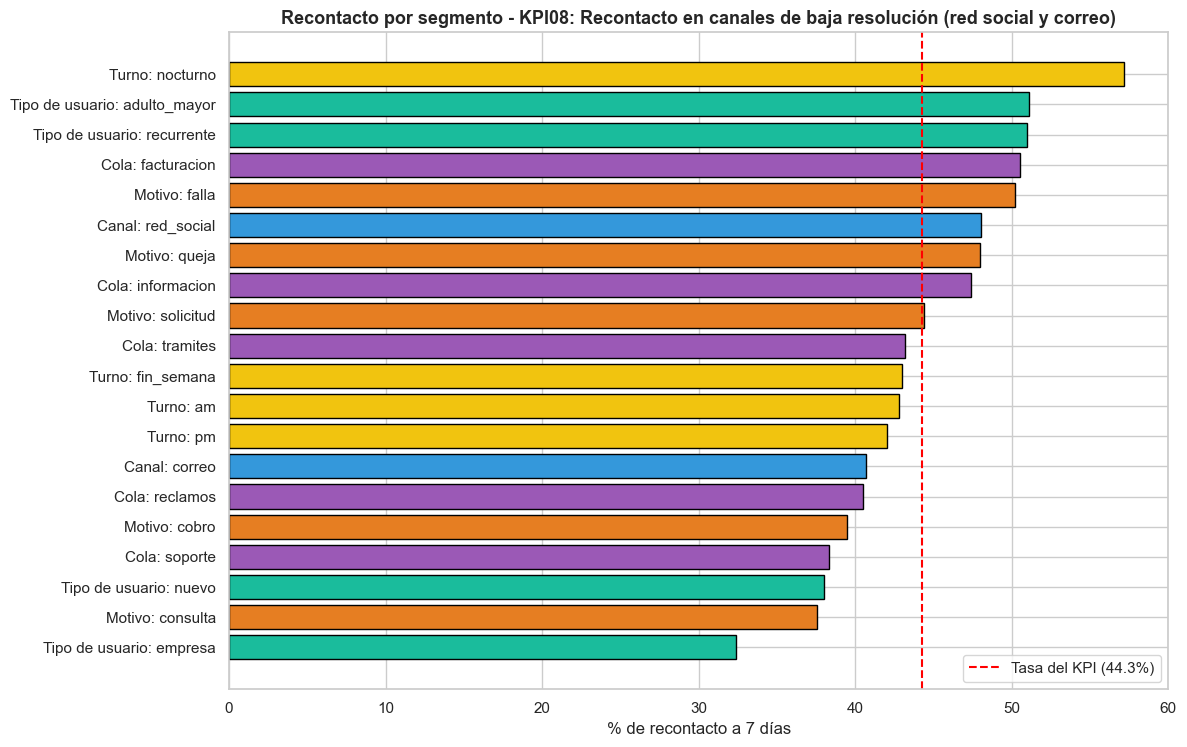


🔺 SEGMENTOS CON MAYOR RECONTACTO:
                     Etiqueta  Casos  Tasa %
              Turno: nocturno    595    57.1
Tipo de usuario: adulto_mayor   1073    51.1
  Tipo de usuario: recurrente   1790    50.9
            Cola: facturacion    960    50.5
                Motivo: falla   1130    50.2

🔻 SEGMENTOS CON MENOR RECONTACTO:
                Etiqueta  Casos  Tasa %
Tipo de usuario: empresa    796    32.4
        Motivo: consulta    895    37.5
  Tipo de usuario: nuevo   1574    38.0
           Cola: soporte   1047    38.3
           Motivo: cobro   1077    39.5


In [13]:
# ============================================================
# Celda 12: Tasa de recontacto por segmento (reglas de negocio)
# ============================================================
print("=" * 70)
print("💼 RECONTACTO POR SEGMENTO")
print("=" * 70)

grupos = {'Canal': 'canal_', 'Motivo': 'motivo_', 'Cola': 'cola_',
          'Tipo de usuario': 'usuario_', 'Turno': 'turno_'}
tasa_kpi = df['es_recontacto'].mean() * 100

filas = []
for g, pref in grupos.items():
    for col in [c for c in df.columns if c.startswith(pref)]:
        m = df[col] == 1
        if m.sum() >= 30:
            filas.append({'Grupo': g, 'Segmento': col.replace(pref, ''),
                          'Casos': int(m.sum()),
                          'Tasa %': df.loc[m, 'es_recontacto'].mean() * 100})
seg = pd.DataFrame(filas).sort_values('Tasa %', ascending=True).reset_index(drop=True)
seg['Etiqueta'] = seg['Grupo'] + ': ' + seg['Segmento']

paleta = {'Canal': '#3498db', 'Motivo': '#e67e22', 'Cola': '#9b59b6',
          'Tipo de usuario': '#1abc9c', 'Turno': '#f1c40f'}
plt.figure(figsize=(12, max(6, len(seg) * 0.38)))
plt.barh(seg['Etiqueta'], seg['Tasa %'], color=[paleta[g] for g in seg['Grupo']], edgecolor='black')
plt.axvline(tasa_kpi, color='red', ls='--', label=f'Tasa del KPI ({tasa_kpi:.1f}%)')
plt.xlabel('% de recontacto a 7 días')
plt.title(f'Recontacto por segmento - {KPI_ID}: {KPI_NOMBRE}', fontsize=13, fontweight='bold')
plt.legend()
plt.tight_layout()
guardar('06_segmentos')
plt.show()

print(f"\n🔺 SEGMENTOS CON MAYOR RECONTACTO:")
print(seg.tail(5).iloc[::-1][['Etiqueta', 'Casos', 'Tasa %']].round(1).to_string(index=False))
print(f"\n🔻 SEGMENTOS CON MENOR RECONTACTO:")
print(seg.head(5)[['Etiqueta', 'Casos', 'Tasa %']].round(1).to_string(index=False))

In [14]:
# ============================================================
# Celda 13: Cifras para el reporte ejecutivo (calculadas)
# El ANÁLISIS se redacta a mano en la celda de texto que sigue.
# ============================================================
ACCIONES = {
    'transferencias': 'Reducir transferencias: mejorar el ruteo para resolver en el primer contacto',
    'espera_seg': 'Reducir el tiempo de espera: ajustar dotación y priorizar colas críticas',
    'casos_previos_30d': 'Seguimiento proactivo a usuarios con casos previos recientes',
    'es_duracion_corta': 'Revisar atenciones muy cortas: pueden cerrarse sin resolver',
    'duracion_seg': 'Revisar la duración de atención frente al tipo de caso',
    'usuario_adulto_mayor': 'Atención asistida y confirmación de resolución a adultos mayores',
    'turno_nocturno': 'Reforzar capacidad de resolución en turno nocturno',
    'canal_red_social': 'Mejorar la resolución en redes sociales o derivar a un canal con trazabilidad',
    'cola_informacion': 'Revisar la calidad de las respuestas en la cola de Información',
    'cola_facturacion': 'Revisar casos de Facturación para resolver en el primer contacto',
    'cola_tramites': 'Simplificar el seguimiento de Trámites',
}
REDUCCION_SUPUESTA = 0.15   # SUPUESTO de trabajo, no es un dato

tasa_kpi = df['es_recontacto'].mean() * 100
n_casos = len(df)
n_rec = int(df['es_recontacto'].sum())
dur_media = df['duracion_seg'].mean()
recall_ = tp / (tp + fn)

horas_rec = n_rec * dur_media / 3600
evitables = n_rec * recall_ * REDUCCION_SUPUESTA
horas_ahorradas = evitables * dur_media / 3600
tasa_proy = tasa_kpi - tasa_kpi * recall_ * REDUCCION_SUPUESTA
brecha_actual = tasa_kpi - META_6M
dif_proy = tasa_proy - META_6M
brecha_ref = tasa_proy - META_RECONTACTO

print("=" * 70)
print(f"📊 CIFRAS DEL REPORTE - {KPI_ID}: {KPI_NOMBRE}")
print("=" * 70)
print(f"""
🎯 OBJETIVO: {OBJETIVO}
🔖 TARGET : {TARGET_DEF}

📊 DATOS
   • Casos del KPI: {n_casos:,}  |  Recontactos: {n_rec:,}  |  Tasa actual (línea base): {tasa_kpi:.2f}%
   • Meta a {PLAZO}: ≤ {META_6M}%  |  Brecha actual: {brecha_actual:.1f} puntos  |  Umbral de alerta: > {UMBRAL_ALERTA}%
   • Referencia de largo plazo (no equivalente): ≤ {META_RECONTACTO:.0f}%
   • Entrenamiento / prueba: {len(X_train):,} / {len(X_test):,}  |  Variables: {X.shape[1]}

🤖 MODELO: Regresión Logística (mejor de 7 por ROC-AUC: {mejor})
   • Accuracy {accuracy:.2%} | Precision {precision:.2%} | Recall {recall:.2%} | F1 {f1:.4f} | ROC-AUC {auc:.4f}
   • CV-AUC (5 particiones): {cv.mean():.4f} ± {cv.std():.4f}
   • Recontactos detectados: {tp:,} de {tp + fn:,} ({recall_:.1%})  |  Alarmas falsas: {fp:,}

⏱️ CARGA OPERATIVA (estimación con la duración media del contacto = {dur_media:.0f} s)
   • Horas-agente que consumen los recontactos del periodo: ≈ {horas_rec:,.0f} h

💰 ESCENARIO ILUSTRATIVO (supuesto declarado: se evita el {REDUCCION_SUPUESTA:.0%} de los recontactos detectados)
   • Recontactos evitables: ≈ {evitables:,.0f}  |  Horas-agente liberadas: ≈ {horas_ahorradas:,.0f} h
   • La tasa bajaría de {tasa_kpi:.1f}% a ≈ {tasa_proy:.1f}%
   • Diferencia frente a la meta de {PLAZO} ({META_6M}%): {dif_proy:+.1f} puntos
   • Distancia que queda a la referencia de largo plazo ({META_RECONTACTO:.0f}%): {brecha_ref:.1f} puntos
   • El {REDUCCION_SUPUESTA:.0%} es un supuesto de trabajo, no un resultado del modelo.
""")

pos = df_coef[df_coef['Coeficiente'] > 0]
prioridades = ['URGENTE', 'ALTO', 'ALTO', 'MEDIO', 'MEDIO', 'MEDIO']
print("🚀 ACCIONES PRIORIZADAS (hipótesis a validar con prueba A/B; prioridad según la asociación)")
print("-" * 70)
n = 0
for _, r in pos.iterrows():
    if r['Variable'] in ACCIONES and n < len(prioridades):
        print(f"   {prioridades[n]:8s} {ACCIONES[r['Variable']]}")
        print(f"            (variable: {r['Variable']} | odds ratio {r['Odds ratio']:.2f} por desv. estándar)")
        n += 1

print("\n🔻 VARIABLES QUE MÁS REDUCEN LA PROBABILIDAD DE RECONTACTO (frente a la categoría de referencia):")
for _, r in df_coef[df_coef['Coeficiente'] < 0].head(3).iterrows():
    print(f"   ↓ {r['Variable']:26s} (odds ratio {r['Odds ratio']:.2f})")

📊 CIFRAS DEL REPORTE - KPI08: Recontacto en canales de baja resolución (red social y correo)

🎯 OBJETIVO: Reducir la tasa de recontacto a 7 días en el Servicio Ciudadano 1800
🔖 TARGET : es_recontacto: 1 = el usuario vuelve a contactar por el mismo motivo en 7 días; 0 = no vuelve; los casos con resultado vacío (no consolidado) se excluyen del modelo

📊 DATOS
   • Casos del KPI: 5,233  |  Recontactos: 2,316  |  Tasa actual (línea base): 44.26%
   • Meta a 6 meses: ≤ 39.1%  |  Brecha actual: 5.2 puntos  |  Umbral de alerta: > 44.3%
   • Referencia de largo plazo (no equivalente): ≤ 22%
   • Entrenamiento / prueba: 4,186 / 1,047  |  Variables: 23

🤖 MODELO: Regresión Logística (mejor de 7 por ROC-AUC: 1. Regresión Logística)
   • Accuracy 79.66% | Precision 76.48% | Recall 77.97% | F1 0.7722 | ROC-AUC 0.8836
   • CV-AUC (5 particiones): 0.8849 ± 0.0088
   • Recontactos detectados: 361 de 463 (78.0%)  |  Alarmas falsas: 111

⏱️ CARGA OPERATIVA (estimación con la duración media del contacto 

# Fase 15: Reporte ejecutivo (redactado por el analista)

**Objetivo.** Reducir la tasa de recontacto a 7 días del Servicio Ciudadano 1800 en los canales de baja resolución (red social y correo), donde hoy es de 44.3%. La meta a 6 meses es ≤ 39.1% (escenario del 15%, supuesto a validar con la dirección) y el umbral de alerta es superar la línea base (44.3%). La referencia de 22% (100% − 78% de resolución en primer contacto) no es equivalente al recontacto a 7 días y se usa solo como referencia de largo plazo.

**Momento de predicción.** El modelo se aplica al cierre de la atención, cuando ya se conocen la espera, la duración, las transferencias y los casos previos del usuario. Ninguna de esas variables incluye información posterior al contacto.

**Hallazgo central.** El modelo (Regresión Logística, ROC-AUC 0.884, accuracy 79.7%) anticipa 8 de cada 10 recontactos en estos canales (recall 78.0%; 361 de 463 en la prueba). Fue el mejor de los 7 modelos comparados y su desempeño es estable (CV-AUC 0.885). La probabilidad de recontacto se asocia sobre todo con tres factores operativos: el número de transferencias (OR 5.2 por desviación estándar), el tiempo de espera (OR 2.4) y los casos previos del usuario en los últimos 30 días (OR 2.4). Una vez controlado el efecto de las demás variables, la cola de Reclamos (OR 0.53) y la cola de Soporte (OR 0.63) muestran menor probabilidad de recontacto.

**Lectura de negocio.** Las transferencias son la señal más fuerte: resolver en el primer contacto, con mejor ruteo, es la acción prioritaria. Después van la reducción de la espera y el seguimiento proactivo a usuarios con casos recientes. Por segmentos, el turno nocturno (57.1%), los adultos mayores (51.1%) y los usuarios recurrentes (50.9%) superan el promedio del KPI; los usuarios empresa (32.4%) son los que menos recontactan. Dentro de estos canales, red social tiene una asociación algo mayor que correo (OR 1.35 frente a correo), pero con un efecto mucho menor que el de las transferencias o la espera.

**Alcance realista.** En el periodo analizado hubo 2,316 recontactos, que consumen ≈ 632 horas-agente. Si se evitara el 15% de los recontactos que el modelo detecta (supuesto de trabajo, no un resultado), se evitarían ≈ 271 recontactos y se liberarían ≈ 74 horas-agente. La tasa bajaría de 44.3% a ≈ 39.1%, **coincidiendo con la meta a 6 meses**, pero todavía quedaría **17.1 puntos por encima de la referencia de largo plazo (22%)**. El modelo ayuda a priorizar a quién y dónde intervenir, pero no basta por sí solo para alcanzar esa referencia.

# Fase 16: Próximos pasos y limitaciones

**Próximos pasos.**
1. Validar con la dirección la meta de recontacto y el criterio de "mismo motivo".
2. Probar las intervenciones con una prueba A/B en las colas con mayor recontacto.
3. Monitorear mensualmente la tasa de recontacto y las métricas del modelo.
4. Reentrenar con datos reales cada trimestre.

**Limitaciones.**
- Los datos son sintéticos. Las relaciones entre variables son supuestos documentados del generador, y su intensidad se calibró para que el modelo quedara en el rango esperado de 75–85%.
- La Regresión Logística gana en parte porque el generador usa una fórmula logística.
- Los coeficientes indican asociación, no causalidad.
- No se dispone de costos por contacto, por lo que el impacto se expresa en casos y horas-agente, con un supuesto del 15% declarado.
- Los 5 KPIs comparten el mismo evento (recontacto) y difieren en la población analizada.
- Parte del recontacto no es evitable (usuarios con consultas nuevas o complejas), por lo que conviene aceptar un piso mínimo.